#1. Flow rate when full water flows in the pipe

θ_max (radians) = 5.278107
θ_max (degrees) = 302.413°
Qmax/Qfull = 1.075706
d/D = 0.938181


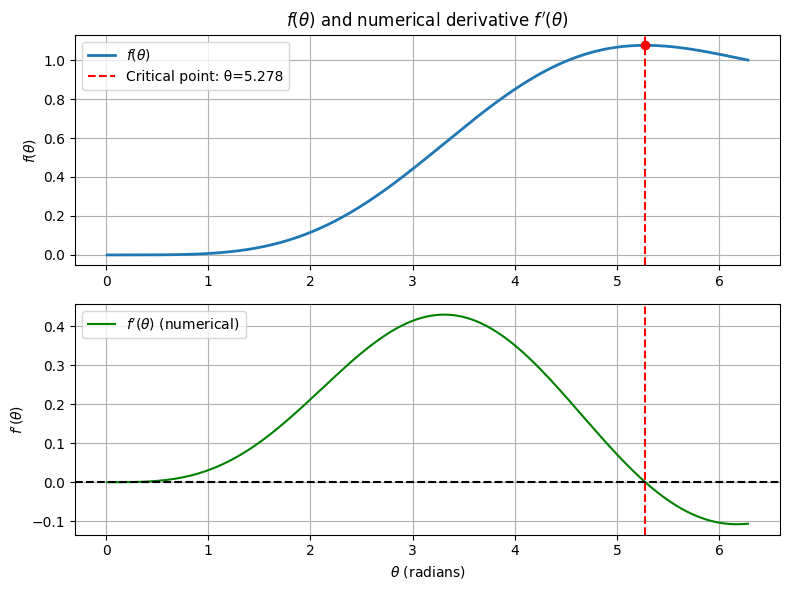

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# -----------------------------------------------------
# 1. f(theta) 정의 (상대유량비 Q/Qf와 동일한 형태)
# -----------------------------------------------------
def f(theta):
    return (1/(2*np.pi)) * ((theta - np.sin(theta))**(5/3)) / (theta**(2/3))

# -----------------------------------------------------
# 2. 수치미분 함수 정의 (중심차분법)
# -----------------------------------------------------
def numerical_derivative(func, x, h=1e-6):
    return (func(x + h) - func(x - h)) / (2*h)

# -----------------------------------------------------
# 3. f'(theta)=0인 지점 찾기
# -----------------------------------------------------
def df(theta):
    return numerical_derivative(f, theta)

theta_root = brentq(df, np.pi, 2*np.pi)
f_root = f(theta_root)

# -----------------------------------------------------
# 4. 수심비(d/D) 계산
# -----------------------------------------------------
# 원형 관에서 θ는 중심각(수면이 이루는 각)이고, d/D = (1 - cos(θ/2))/2
d_over_D = 0.5 * (1 - np.cos(theta_root / 2))

# -----------------------------------------------------
# 5. 결과 출력
# -----------------------------------------------------
print(f"θ_max (radians) = {theta_root:.6f}")
print(f"θ_max (degrees) = {np.degrees(theta_root):.3f}°")
print(f"Qmax/Qfull = {f_root:.6f}")
print(f"d/D = {d_over_D:.6f}")

# -----------------------------------------------------
# 6. 시각화: f(θ) 곡선과 최대점 표시
# -----------------------------------------------------
theta_vals = np.linspace(0.01, 2*np.pi, 400)
f_vals = f(theta_vals)
df_vals = np.gradient(f_vals, theta_vals)

plt.figure(figsize=(8,6))
plt.subplot(2,1,1)
plt.plot(theta_vals, f_vals, label=r"$f(\theta)$", linewidth=2)
plt.scatter(theta_root, f_root, color='r', zorder=5)
plt.axvline(theta_root, color='r', linestyle='--', label=fr"Critical point: θ={theta_root:.3f}")
plt.ylabel(r"$f(\theta)$")
plt.title(r"$f(\theta)$ and numerical derivative $f'(\theta)$")
plt.legend()
plt.grid(True)

plt.subplot(2,1,2)
plt.plot(theta_vals, df_vals, color='g', label=r"$f'(\theta)$ (numerical)")
plt.axhline(0, color='k', linestyle='--')
plt.axvline(theta_root, color='r', linestyle='--')
plt.xlabel(r"$\theta$ (radians)")
plt.ylabel(r"$f'(\theta)$")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


#2. Velocity when full water flows in the pipe

theta* (radians) = 4.4934094581
theta* (degrees) = 257.453°
Vmax/VF          = 1.140029
d/D               = 0.812803


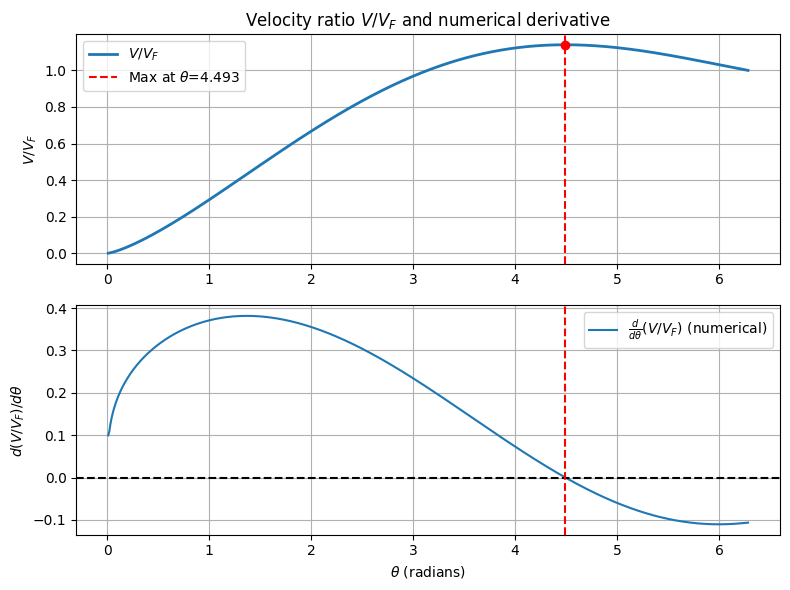

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# -----------------------------------------------------
# 1) 유속비 V/V_F 정의
#    V/V_F = ((θ - sinθ) / θ)^(2/3),  0 < θ ≤ 2π
# -----------------------------------------------------
def v_ratio(theta):
    return ((theta - np.sin(theta)) / theta) ** (2/3)

# -----------------------------------------------------
# 2) 수치미분(중심차분) 함수
# -----------------------------------------------------
def numerical_derivative(func, x, h=1e-6):
    return (func(x + h) - func(x - h)) / (2*h)

# 유속비의 도함수를 수치적으로 계산하는 래퍼
def dv(theta):
    return numerical_derivative(v_ratio, theta)

# -----------------------------------------------------
# 3) 최대점 찾기: dv(θ) = 0을 (π, 2π)에서 탐색
#    (이 구간에서 유일한 해가 존재; 실제로 tanθ = θ 근과 일치)
# -----------------------------------------------------
theta_star = brentq(dv, np.pi, 2*np.pi)
v_star = v_ratio(theta_star)

# -----------------------------------------------------
# 4) 수심비 d/D 계산 (반드시 1/2 곱해줘야 함!)
#    d/D = (1 - cos(θ/2)) / 2
# -----------------------------------------------------
d_over_D = 0.5 * (1 - np.cos(theta_star / 2))

# -----------------------------------------------------
# 5) 결과 출력
#    이론값: θ* ≈ 4.493,  d/D ≈ 0.81,  Vmax/VF ≈ 1.14
# -----------------------------------------------------
print(f"theta* (radians) = {theta_star:.10f}")
print(f"theta* (degrees) = {np.degrees(theta_star):.3f}°")
print(f"Vmax/VF          = {v_star:.6f}")
print(f"d/D               = {d_over_D:.6f}")

# -----------------------------------------------------
# 6) 시각화: V/VF 곡선과 수치미분, 최대점 표시
# -----------------------------------------------------
theta_vals = np.linspace(0.01, 2*np.pi, 600)
v_vals = v_ratio(theta_vals)
dv_vals = np.gradient(v_vals, theta_vals)   # 시각화용 근사 도함수

plt.figure(figsize=(8,6))

# (1) V/VF plot
plt.subplot(2,1,1)
plt.plot(theta_vals, v_vals, linewidth=2, label=r"$V/V_F$")
plt.scatter(theta_star, v_star, color='r', zorder=5)
plt.axvline(theta_star, color='r', linestyle='--', label=fr"Max at $\theta$={theta_star:.3f}")
plt.ylabel(r"$V/V_F$")
plt.title(r"Velocity ratio $V/V_F$ and numerical derivative")
plt.legend()
plt.grid(True)

# (2) d(V/VF)/dθ plot (numerical)
plt.subplot(2,1,2)
plt.plot(theta_vals, dv_vals, label=r"$\frac{d}{d\theta}(V/V_F)$ (numerical)")
plt.axhline(0, color='k', linestyle='--')
plt.axvline(theta_star, color='r', linestyle='--')
plt.xlabel(r"$\theta$ (radians)")
plt.ylabel(r"$d(V/V_F)/d\theta$")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
